This code loads the Edgar data and explores the peak tester applied to different gases

Note that Emissions|GHG|Total excludes LULUCF
Emissions|GHG|Total_incl_LULUCF includes LULUCF

In [1]:
import os, sys
sys.path.append('../scripts')

from peak_tester import EmissionsPeakTest
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas_indexing as pix
from pandas_indexing import *
import openpyxl

import joblib

from helper_functions import HiddenPrints, segment_by_peaks, combine_countries, find_peak_in 

In [ ]:
# # Load Edgar data (only use once)

# see scripts (edgar_emissions.py) for details on how this is done with LULUCF

# XLSX_PATH = '../data/raw/EDGAR_2026_GHG_booklet_2026_with_LULUCF.xlsx'
# OUT_PATH = '../data/processed/edgar_emissions.csv'

# # Gas name mapping to clean variable strings
# GAS_LABELS = {
#     'CO2': 'CO2',
#     'GWP_100_AR5_CH4': 'CH4',
#     'GWP_100_AR5_N2O': 'N2O',
#     'GWP_100_AR5_F-gases': 'F-gases',
# }

# UNIT = 'Mt CO2eq/yr'

# print("Loading EDGAR xlsx...")
# wb = openpyxl.load_workbook(XLSX_PATH, read_only=True, data_only=True)

# # ── 1. GHG_totals_by_country → Emissions|GHG|Total (all gases, all sectors) ──
# ws_totals = wb['GHG_totals_by_country']
# rows_totals = list(ws_totals.iter_rows(values_only=True))
# header_totals = rows_totals[0]
# years_totals = [c for c in header_totals if isinstance(c, int)]

# records = []

# for row in rows_totals[1:]:
#     code, name = row[0], row[1]
#     if not code or not name:
#         continue
#     vals = {yr: row[i+2] for i, yr in enumerate(years_totals)}
#     records.append({
#         'region': code,
#         'region_name': name,
#         'variable': 'Emissions|GHG|Total',
#         'unit': UNIT,
#         **vals
#     })

# print(f"  Totals: {len(records)} rows")

# # ── 2. GHG_by_sector_and_country → per gas per sector + per gas total ──
# ws_sector = wb['GHG_by_sector_and_country']
# rows_sector = list(ws_sector.iter_rows(values_only=True))
# header_sector = rows_sector[0]
# years_sector = [c for c in header_sector if isinstance(c, int)]

# # Load into a dict keyed by (gas, sector, code, name) → {year: val}
# sector_data = {}
# for row in rows_sector[1:]:
#     gas, sector, code, name = row[0], row[1], row[2], row[3]
#     if not all([gas, sector, code, name]):
#         continue
#     key = (gas, sector, code, name)
#     sector_data[key] = {yr: row[i+4] for i, yr in enumerate(years_sector)}

# # Emit one row per (gas, sector, region)
# for (gas, sector, code, name), vals in sector_data.items():
#     gas_label = GAS_LABELS.get(gas, gas)
#     records.append({
#         'region': code,
#         'region_name': name,
#         'variable': f'Emissions|{gas_label}|{sector}',
#         'unit': UNIT,
#         **vals
#     })

# print(f"  After sector rows: {len(records)} rows")

# # ── 3. Per-gas totals across all sectors ──
# # Group by (gas, code, name) and sum across sectors
# from collections import defaultdict
# gas_totals = defaultdict(lambda: defaultdict(float))  # (gas, code, name) → {year: sum}
# gas_names = {}  # (gas, code) → name

# for (gas, sector, code, name), vals in sector_data.items():
#     key = (gas, code, name)
#     for yr, v in vals.items():
#         if v is not None:
#             gas_totals[key][yr] += v
#         # If v is None we leave it out of the sum for now; could also track missing

# for (gas, code, name), yr_vals in gas_totals.items():
#     gas_label = GAS_LABELS.get(gas, gas)
#     records.append({
#         'region': code,
#         'region_name': name,
#         'variable': f'Emissions|{gas_label}|Total',
#         'unit': UNIT,
#         **yr_vals
#     })

# print(f"  After gas total rows: {len(records)} rows")

# # ── 4. Build DataFrame and write CSV ──
# all_years = sorted(set(years_totals) | set(years_sector))
# df = pd.DataFrame(records)
# df = df.set_index(['region', 'region_name', 'variable', 'unit'])

# # Reorder columns to be sorted years
# year_cols = sorted([c for c in df.columns if isinstance(c, int)])
# df = df[year_cols]

# # change global total name to 'WLD'
# df.index = df.index.set_levels(
#     df.index.levels[0].str.replace('GLOBAL TOTAL', 'WLD'),
#     level=0
# )
# df.index = df.index.set_levels(
#     df.index.levels[1].str.replace('GLOBAL TOTAL', 'WLD'),
#     level=1
# )

# df.to_csv(OUT_PATH)
# print(f"\nDone! Written to {OUT_PATH}")
# print(f"Shape: {df.shape}")
# print(f"\nSample variables:")
# for v in sorted(df.index.get_level_values('variable').unique()):
#     print(f"  {v}")
# print(f"\nSample regions (first 5 + EU27 + WLD):")
# regions = df.index.get_level_values('region').unique()
# for r in list(regions[:5]) + ['EU27', 'WLD']:
#     if r in regions:
#         print(f"  {r}")

Loading EDGAR xlsx...
  Totals: 212 rows
  After sector rows: 5068 rows
  After gas total rows: 5855 rows

Done! Written to ../data/processed/edgar_emissions.csv
Shape: (5855, 56)

Sample variables:
  Emissions|CH4|Agriculture
  Emissions|CH4|Buildings
  Emissions|CH4|Fuel Production
  Emissions|CH4|Industrial Combustion
  Emissions|CH4|Power Industry
  Emissions|CH4|Processes
  Emissions|CH4|Total
  Emissions|CH4|Transport
  Emissions|CH4|Waste
  Emissions|CO2|Agriculture
  Emissions|CO2|Buildings
  Emissions|CO2|Fuel Production
  Emissions|CO2|Industrial Combustion
  Emissions|CO2|Power Industry
  Emissions|CO2|Processes
  Emissions|CO2|Total
  Emissions|CO2|Transport
  Emissions|CO2|Waste
  Emissions|F-gases|Processes
  Emissions|F-gases|Total
  Emissions|GHG|Total
  Emissions|N2O|Agriculture
  Emissions|N2O|Buildings
  Emissions|N2O|Fuel Production
  Emissions|N2O|Industrial Combustion
  Emissions|N2O|Power Industry
  Emissions|N2O|Processes
  Emissions|N2O|Total
  Emissions|N2O|Tr

In [2]:
edgar = pd.read_csv('../data/processed/edgar_emissions_incl_lulucf.csv', index_col=[0,1,2,3])
edgar.columns = edgar.columns.astype(int)
edgar.index.get_level_values('variable').unique()

Index(['Emissions|GHG|Total', 'Emissions|CO2|Agriculture',
       'Emissions|CO2|Buildings', 'Emissions|CO2|Fuel Production',
       'Emissions|CO2|Industrial Combustion', 'Emissions|CO2|Power Industry',
       'Emissions|CO2|Processes', 'Emissions|CO2|Transport',
       'Emissions|CO2|Waste', 'Emissions|CH4|Agriculture',
       'Emissions|CH4|Buildings', 'Emissions|CH4|Fuel Production',
       'Emissions|CH4|Industrial Combustion', 'Emissions|CH4|Power Industry',
       'Emissions|CH4|Processes', 'Emissions|CH4|Transport',
       'Emissions|CH4|Waste', 'Emissions|F-gases|Processes',
       'Emissions|N2O|Agriculture', 'Emissions|N2O|Buildings',
       'Emissions|N2O|Fuel Production', 'Emissions|N2O|Industrial Combustion',
       'Emissions|N2O|Power Industry', 'Emissions|N2O|Processes',
       'Emissions|N2O|Transport', 'Emissions|N2O|Waste', 'Emissions|CO2|Total',
       'Emissions|CH4|Total', 'Emissions|F-gases|Total', 'Emissions|N2O|Total',
       'Emissions|GHG|LULUCF', 'Emissions

In [3]:
# Add data for total energy sector CO2 (excluding agriculture and waste)
energy_sectors = [
    'Fuel Production',
    'Power Industry', 
    'Industrial Combustion',
    'Buildings',
    'Transport'
]

# Filter to CO2, energy sectors only
energy_co2 = edgar[
    (edgar.index.get_level_values('variable').str.startswith('Emissions|CO2|')) &
    (edgar.index.get_level_values('variable').str.split('|').str[-1].isin(energy_sectors))
]

# Sum across sectors for each region
energy_co2_total = (
    energy_co2
    .groupby(level=['region', 'region_name'])
    .sum()
)

# Add the variable and unit back as index levels
energy_co2_total['variable'] = 'Emissions|CO2|Energy'
energy_co2_total['unit'] = 'Mt CO2eq/yr'
energy_co2_total = energy_co2_total.reset_index().set_index(
    ['region', 'region_name', 'variable', 'unit']
)
energy_co2_total.columns = energy_co2_total.columns.astype(int)

<Axes: >

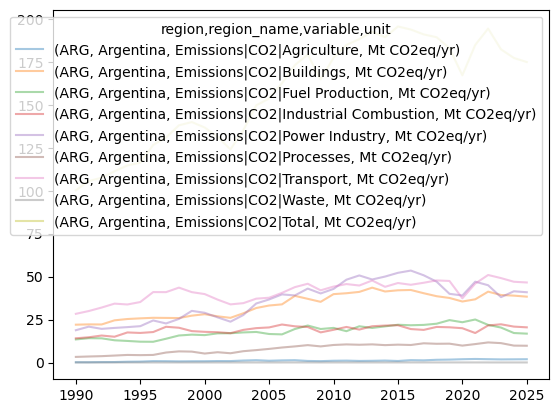

In [32]:
idx = edgar.index[
    (edgar.index.get_level_values('region') == 'ARG') &
    (edgar.index.get_level_values('variable').str.startswith('Emissions|CO2|'))
]
edgar.loc[idx, 1990:].T.plot(alpha=0.4)

In [73]:
# energy_co2_total.to_csv('../data/processed/edgar_energy_co2.csv')
# # Add country groups to energy data
G20_ISOS = ['AUS','ARG','BRA','CAN','CHN','EU27','IND','IDN','JPN','MEX','RUS','SAU','KOR','TUR','GBR','USA','ZAF'] 

# # Add G20
# combine_countries(G20_ISOS, 'edgar_energy_co2.csv', countries_name='G20')

# # Add G20_excl_CHN 
G20_excl_CHN = [item for item in G20_ISOS if item != 'CHN']
# combine_countries(G20_excl_CHN, 'edgar_energy_co2.csv', countries_name='G20_excl_CHN')

edgar_energy = pd.read_csv('../data/processed/edgar_energy_co2.csv', index_col=[0,1,2,3])
edgar_energy.columns = edgar_energy.columns.astype(int)


In [147]:
# Add country groups to total GHG data
# combine_countries(G20_ISOS, 'edgar_emissions_incl_lulucf.csv', countries_name = 'G20')

# Add G20_excl_CHN 
# G20_excl_CHN = [item for item in G20_ISOS if item != 'CHN']
# combine_countries(G20_excl_CHN, 'edgar_emissions_incl_lulucf.csv', countries_name='G20_excl_CHN')

<Axes: >

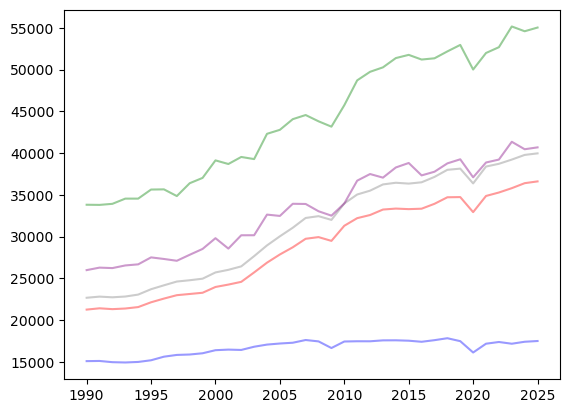

In [6]:
# Take a look at the data

edgar.loc[('WLD', slice(None), 'Emissions|CO2|Total', slice(None)), 1990:].T.plot(legend=False, color='grey', alpha=0.4)
edgar.loc[('WLD', slice(None), 'Emissions|GHG|Total_incl_LULUCF', slice(None)), 1990:].T.plot(legend=False, color='green', alpha=0.4, ax=plt.gca())
energy_co2_total.loc[('WLD', slice(None), 'Emissions|CO2|Energy', slice(None)), 1990:].T.plot(legend=False, color='red', alpha=0.4, ax=plt.gca()) 

edgar.loc[('G20', slice(None), 'Emissions|GHG|Total_incl_LULUCF', slice(None)), 1990:].T.plot(legend=False, color='purple', alpha=0.4, ax=plt.gca())
edgar_energy.loc[('G20_excl_CHN', slice(None), 'Emissions|CO2|Energy', slice(None)), 1990:].T.plot(legend=False, color='blue', alpha=0.4, ax = plt.gca())

# Run peak tests

In [7]:
# Function to run peak tests

def run_expanding_window_test(
    isos,
    csv_path,
    joblib_path,
    data_file,
    variable,
    method='slope',           # 'slope' or 'sequential'
    year_range=range(1990, 2026),
    noise_method='broken_trend',
    noise_type='t-dist',
    ignore_years=[2020],
    redo=False,
):
    """
    Run expanding window peak detection for a list of ISOs, merging with
    any existing results and re-saving.

    Args:
        isos:         list of ISO codes to run
        csv_path:     path to save/load probability results CSV
        joblib_path:  path to save/load peak tester objects
        data_file:    emissions data CSV to load
        variable:     emissions variable string e.g. 'Emissions|CO2|Total'
        method:       'slope' or 'sequential'
        year_range:   range of years to load historical data for and run the analysis
        noise_method: passed to characterize_noise
        noise_type:   passed to characterize_noise
        ignore_years: passed to characterize_noise
        redo:         if True, re-run even if iso already in results

    Returns:
        testers:      dict of EmissionsPeakTest objects keyed by iso
        prob_df:      DataFrame of peak probabilities keyed by iso
    """
    # Load existing results
    try:
        testers = joblib.load(joblib_path)
        prob_df = pd.read_csv(csv_path, index_col=0)
        print(f"Loaded existing results for: {list(prob_df.columns)}")
    except FileNotFoundError:
        testers = dict()
        prob_df = pd.DataFrame()
        print("No existing results found, starting fresh")

    # Determine which ISOs to run
    existing = list(prob_df.columns) if not prob_df.empty else []
    if redo:
        isos_to_run = isos
    else:
        isos_to_run = [iso for iso in isos if iso not in existing]

    if not isos_to_run:
        print("All requested ISOs already in results — nothing to run")
        return testers, prob_df

    for iso in isos_to_run:
        print(f"\n___ Performing analysis for {iso} ({method}) ___\n")
        peak_tester_iso = EmissionsPeakTest()
        peak_tester_iso.load_historical_data(
            data_file, region=iso,
            variable=variable, year_range=year_range
        )
        peak_tester_iso.characterize_noise(
            method=noise_method, noise_type=noise_type,
            ignore_years=ignore_years
        )
        peak_tester_iso.create_noise_generator()

        p_likelihood_series = pd.Series(dtype=float)
        hist_data = peak_tester_iso.historical_data

        if method == 'slope':
            with HiddenPrints():
                for year in range(year_range.start + 1, year_range.stop):
                    peak_year = find_peak_in(hist_data.index.min(), year, hist_data)
                    if peak_year == year:
                        test_data = hist_data.loc[range(year - 1, year + 1)]
                    else:
                        test_data = hist_data.loc[range(peak_year, year + 1)]

                    peak_tester_iso.set_test_data(test_data).run_complete_bootstrap_test(
                        bootstrap_method='ar_bootstrap')
                    p_val = 1 - peak_tester_iso.bootstrap_results['p_value_one_tail']
                    p_likelihood_series.loc[year] = p_val

        elif method == 'sequential':
            with HiddenPrints():
                peak_regimes = segment_by_peaks(peak_tester_iso.historical_data)
                peak_regimes.append(2025)
                p_array = pd.Series(index=year_range)
                for ix in range(len(peak_regimes)-1):
                        test_data = hist_data.loc[(range(peak_regimes[ix],peak_regimes[ix+1]+1))]
                        peak_tester_iso.set_test_data(test_data).run_complete_bootstrap_test(
                                bootstrap_method='ar_bootstrap',test_sequential=True
                        )
                        p_array.loc[peak_regimes[ix]+1:peak_regimes[ix+1]] = peak_tester_iso.bootstrap_results['p_sequential_steps']
                p_likelihood_series = 1 - p_array

        prob_df[iso] = p_likelihood_series
        testers[iso] = peak_tester_iso 


    # Save merged results
    prob_df.to_csv(csv_path)
    joblib.dump(testers, joblib_path)
    print(f"\nSaved results for: {list(prob_df.columns)}")

    return testers, prob_df

In [40]:
# CO2 Total — slope
method = 'slope'


co2_total_testers, co2_total_slope = run_expanding_window_test(
    isos= G20_ISOS,
    csv_path= f"../outputs/data/edgar_analysis/co2_growing_window_{method}.csv",
    joblib_path=f"../outputs/data/edgar_analysis/co2_growing_window_{method}.joblib",
    data_file='edgar_emissions.csv',
    variable='Emissions|CO2|Total',
    method=method,
)

Using white noise generator with mean=0,  σ=311.545
Using white noise generator with mean=0,  σ=140.864
Using white noise generator with mean=0,  σ=110.633
Using AR(1) noise generator with φ=0.47, mean=-0.000, sigma=51.726
Using AR(1) noise generator with φ=0.63, mean=-0.000, sigma=5.111
Using AR(1) noise generator with φ=0.43, mean=-0.000, sigma=5.202
Using AR(1) noise generator with φ=0.42, mean=0.000, sigma=14.033
Using white noise generator with mean=0,  σ=12.474
Using AR(1) noise generator with φ=0.49, mean=-0.000, sigma=67.201
Using white noise generator with mean=0,  σ=9.884
Using AR(1) noise generator with φ=0.47, mean=-0.000, sigma=26.110
Using white noise generator with mean=0,  σ=10.926
Using white noise generator with mean=0,  σ=40.214
Using AR(1) noise generator with φ=0.49, mean=-0.000, sigma=9.589
Using AR(1) noise generator with φ=0.36, mean=0.000, sigma=15.927
Using AR(1) noise generator with φ=0.31, mean=0.000, sigma=11.363
Using white noise generator with mean=0,  σ=

In [41]:
# CO2 Total
method = 'sequential'

co2_total_seq_testers, co2_total_sequential = run_expanding_window_test(
    isos=['WLD'],
    csv_path= f"../outputs/data/edgar_analysis/co2_growing_window_{method}.csv",
    joblib_path=f"../outputs/data/edgar_analysis/co2_growing_window_{method}.joblib",
    data_file='edgar_emissions.csv',
    variable='Emissions|CO2|Total',
    method=method,
)

Using white noise generator with mean=0,  σ=311.545
Using AR(1) noise generator with φ=0.63, mean=-0.000, sigma=5.111
Using AR(1) noise generator with φ=0.43, mean=-0.000, sigma=5.202
Using AR(1) noise generator with φ=0.42, mean=0.000, sigma=14.033
Using white noise generator with mean=0,  σ=12.474
Using white noise generator with mean=0,  σ=140.864
Using AR(1) noise generator with φ=0.49, mean=-0.000, sigma=67.201
Using AR(1) noise generator with φ=0.47, mean=-0.000, sigma=51.726
Using white noise generator with mean=0,  σ=9.884
Using AR(1) noise generator with φ=0.47, mean=-0.000, sigma=26.110
Using white noise generator with mean=0,  σ=10.926
Using white noise generator with mean=0,  σ=40.214
Using AR(1) noise generator with φ=0.49, mean=-0.000, sigma=9.589
Using AR(1) noise generator with φ=0.36, mean=0.000, sigma=15.927
Using AR(1) noise generator with φ=0.31, mean=0.000, sigma=11.363
Using white noise generator with mean=0,  σ=11.929
Using white noise generator with mean=0,  σ=1

In [75]:
# CO2 Energy
method = 'slope'

co2_energy_slope_testers, co2_energy_slope = run_expanding_window_test(
    isos=['G20'],
    csv_path= f"../outputs/data/edgar_analysis/co2_energy_growing_window_{method}.csv",
    joblib_path=f"../outputs/data/edgar_analysis/co2_energy_growing_window_{method}.joblib",
    data_file='edgar_energy_co2.csv',
    variable='Emissions|CO2|Energy',
    method=method,
)

Using white noise generator with mean=0,  σ=298.259
Using AR(1) noise generator with φ=0.54, mean=0.000, sigma=140.496
Using white noise generator with mean=0,  σ=107.222
Using AR(1) noise generator with φ=0.44, mean=0.000, sigma=50.155
Using white noise generator with mean=0,  σ=244.234
Using white noise generator with mean=0,  σ=214.457
Using AR(1) noise generator with φ=0.62, mean=-0.000, sigma=5.153
Using AR(1) noise generator with φ=0.41, mean=-0.000, sigma=4.865
Using white noise generator with mean=0,  σ=8.061
Using white noise generator with mean=0,  σ=10.828
Using AR(1) noise generator with φ=0.47, mean=-0.000, sigma=62.175
Using white noise generator with mean=0,  σ=9.372
Using AR(1) noise generator with φ=0.49, mean=0.000, sigma=24.146
Using AR(1) noise generator with φ=0.31, mean=0.000, sigma=11.884
Using white noise generator with mean=0,  σ=36.562
Using AR(1) noise generator with φ=0.48, mean=0.000, sigma=8.707
Using AR(1) noise generator with φ=0.43, mean=0.000, sigma=15

In [76]:
# CO2 Energy
method = 'sequential'

co2_energy_seq_testers, co2_energy_sequential = run_expanding_window_test(
    isos=['G20'],
    csv_path= f"../outputs/data/edgar_analysis/co2_energy_growing_window_{method}.csv",
    joblib_path=f"../outputs/data/edgar_analysis/co2_energy_growing_window_{method}.joblib",
    data_file='edgar_energy_co2.csv',
    variable='Emissions|CO2|Energy',
    method=method,
)

Using white noise generator with mean=0,  σ=298.259
Using AR(1) noise generator with φ=0.62, mean=-0.000, sigma=5.153
Using AR(1) noise generator with φ=0.41, mean=-0.000, sigma=4.865
Using white noise generator with mean=0,  σ=8.061
Using white noise generator with mean=0,  σ=10.828
Using AR(1) noise generator with φ=0.54, mean=0.000, sigma=140.496
Using AR(1) noise generator with φ=0.47, mean=-0.000, sigma=62.175
Using AR(1) noise generator with φ=0.44, mean=-0.000, sigma=50.155
Using white noise generator with mean=0,  σ=9.372
Using AR(1) noise generator with φ=0.49, mean=0.000, sigma=24.146
Using AR(1) noise generator with φ=0.31, mean=0.000, sigma=11.884
Using white noise generator with mean=0,  σ=36.562
Using AR(1) noise generator with φ=0.48, mean=0.000, sigma=8.707
Using AR(1) noise generator with φ=0.43, mean=0.000, sigma=15.500
Using AR(1) noise generator with φ=0.34, mean=-0.000, sigma=10.280
Using white noise generator with mean=0,  σ=11.973
Using white noise generator with

In [45]:
# GHG total (excl lulucf)
method = 'slope'

ghg_slope_testers, ghg_slope = run_expanding_window_test(
    isos=['WLD'],
    csv_path= f"../outputs/data/edgar_analysis/ghg_growing_window_{method}.csv",
    joblib_path=f"../outputs/data/edgar_analysis/ghg_growing_window_{method}.joblib",
    data_file='edgar_emissions.csv',
    variable='Emissions|GHG|Total',
    method=method,
)

Using AR(1) noise generator with φ=0.82, mean=0.000, sigma=530.257
Loaded existing results for: ['WLD']
All requested ISOs already in results — nothing to run


In [66]:
# GHG total (incl lulucf)
method = 'slope'

ghglu_slope_testers, ghglu_slope = run_expanding_window_test(
    isos=G20_ISOS,
    csv_path= f"../outputs/data/edgar_analysis/ghglu_growing_window_{method}.csv",
    joblib_path=f"../outputs/data/edgar_analysis/ghglu_growing_window_{method}.joblib",
    data_file='edgar_emissions_incl_lulucf.csv',
    variable='Emissions|GHG|Total_incl_LULUCF',
    method=method,
)

Using white noise generator with mean=0,  σ=784.311
Using white noise generator with mean=0,  σ=332.019
Using white noise generator with mean=0,  σ=29.403
Using AR(1) noise generator with φ=0.72, mean=0.000, sigma=242.771
Using white noise generator with mean=0,  σ=103.641
Using AR(1) noise generator with φ=0.46, mean=0.000, sigma=164.533
Using AR(1) noise generator with φ=0.46, mean=-0.000, sigma=82.891
Using AR(1) noise generator with φ=0.41, mean=-0.000, sigma=75.599
Using white noise generator with mean=0,  σ=339.169
Using white noise generator with mean=0,  σ=21.179
Using white noise generator with mean=0,  σ=25.069
Using white noise generator with mean=0,  σ=143.333
Using AR(1) noise generator with φ=0.44, mean=-0.000, sigma=10.815
Using AR(1) noise generator with φ=0.34, mean=0.000, sigma=16.049
Using AR(1) noise generator with φ=0.45, mean=0.000, sigma=10.925
Using white noise generator with mean=0,  σ=11.686
Using AR(1) noise generator with φ=0.29, mean=-0.000, sigma=147.885
U

In [67]:
# GHG total (incl lulucf)
method = 'sequential'

ghglu_seq_testers, ghglu_sequential = run_expanding_window_test(
    isos=G20_ISOS,
    csv_path= f"../outputs/data/edgar_analysis/ghglu_growing_window_{method}.csv",
    joblib_path=f"../outputs/data/edgar_analysis/ghglu_growing_window_{method}.joblib",
    data_file='edgar_emissions_incl_lulucf.csv',
    variable='Emissions|GHG|Total_incl_LULUCF',
    method=method,
)

Using white noise generator with mean=0,  σ=784.311
Using white noise generator with mean=0,  σ=332.019
Using white noise generator with mean=0,  σ=29.403
Using AR(1) noise generator with φ=0.72, mean=0.000, sigma=242.771
Using white noise generator with mean=0,  σ=103.641
Using AR(1) noise generator with φ=0.46, mean=0.000, sigma=164.533
Using AR(1) noise generator with φ=0.46, mean=-0.000, sigma=82.891
Using AR(1) noise generator with φ=0.41, mean=-0.000, sigma=75.599
Using white noise generator with mean=0,  σ=339.169
Using white noise generator with mean=0,  σ=21.179
Using white noise generator with mean=0,  σ=25.069
Using white noise generator with mean=0,  σ=143.333
Using AR(1) noise generator with φ=0.44, mean=-0.000, sigma=10.815
Using AR(1) noise generator with φ=0.34, mean=0.000, sigma=16.049
Using AR(1) noise generator with φ=0.45, mean=0.000, sigma=10.925
Using white noise generator with mean=0,  σ=11.686
Using AR(1) noise generator with φ=0.29, mean=-0.000, sigma=147.885
U

In [48]:
# CO2 power
method = 'slope'

co2power_slope_testers, co2power_slope = run_expanding_window_test(
    isos=['G20', 'G20_excl_CHN'],
    csv_path= f"../outputs/data/edgar_analysis/co2_power_growing_window_{method}.csv",
    joblib_path=f"../outputs/data/edgar_analysis/co2_power_growing_window_{method}.joblib",
    data_file='edgar_emissions_incl_lulucf.csv',
    variable='Emissions|CO2|Power Industry',
    method=method,
)

Using white noise generator with mean=0,  σ=147.357
Using AR(1) noise generator with φ=0.55, mean=0.000, sigma=114.358
Using AR(1) noise generator with φ=0.45, mean=-0.000, sigma=37.448
Using AR(1) noise generator with φ=0.46, mean=-0.000, sigma=5.232
Using white noise generator with mean=0,  σ=2.410
Using white noise generator with mean=0,  σ=6.665
Using AR(1) noise generator with φ=0.40, mean=0.000, sigma=4.896
Using white noise generator with mean=0,  σ=27.914
Using AR(1) noise generator with φ=-0.30, mean=-0.000, sigma=4.684
Using white noise generator with mean=0,  σ=12.547
Using white noise generator with mean=0,  σ=5.041
Using AR(1) noise generator with φ=0.59, mean=-0.000, sigma=34.671
Using white noise generator with mean=0,  σ=4.518
Using white noise generator with mean=0,  σ=7.234
Using white noise generator with mean=0,  σ=3.736
Using white noise generator with mean=0,  σ=5.652
Using white noise generator with mean=0,  σ=50.627
Using AR(1) noise generator with φ=0.32, mean=

In [49]:
# CO2 power
method = 'sequential'

co2power_seq_testers, co2power_sequential = run_expanding_window_test(
    isos=G20_ISOS,
    csv_path= f"../outputs/data/edgar_analysis/co2_power_growing_window_{method}.csv",
    joblib_path=f"../outputs/data/edgar_analysis/co2_power_growing_window_{method}.joblib",
    data_file='edgar_emissions_incl_lulucf.csv',
    variable='Emissions|CO2|Power Industry',
    method=method,
)

Using white noise generator with mean=0,  σ=147.357
Using AR(1) noise generator with φ=0.46, mean=-0.000, sigma=5.232
Using white noise generator with mean=0,  σ=2.410
Using white noise generator with mean=0,  σ=6.665
Using AR(1) noise generator with φ=0.40, mean=0.000, sigma=4.896
Using AR(1) noise generator with φ=0.55, mean=0.000, sigma=114.358
Using white noise generator with mean=0,  σ=27.914
Using AR(1) noise generator with φ=0.45, mean=-0.000, sigma=37.448
Using AR(1) noise generator with φ=-0.30, mean=-0.000, sigma=4.684
Using white noise generator with mean=0,  σ=12.547
Using white noise generator with mean=0,  σ=5.041
Using AR(1) noise generator with φ=0.59, mean=-0.000, sigma=34.671
Using white noise generator with mean=0,  σ=4.518
Using white noise generator with mean=0,  σ=7.234
Using white noise generator with mean=0,  σ=3.736
Using white noise generator with mean=0,  σ=5.652
Using white noise generator with mean=0,  σ=50.627
Using AR(1) noise generator with φ=0.32, mean=

# Plotting

In [61]:
# Plot for each country, showing historical data and probability of peaking
def results_plot(prob_df_slope: pd.DataFrame = None,
                 prob_df_sequential: pd.DataFrame = None,
                 countries: list = None,
                 peak_years: pd.Series = None,
                 historical_data: str = 'edgar_emissions_inc_lulucf.csv',
                 variable: str = 'Emissions|CO2|Total',
                 year_start: float = 1990,
                 title: str = "Peaking test"):
    """
    Generic plotter for emissions vs. probability of peaking.
    
    Args:
        prob_df_slope:      DataFrame of slope method probabilities (optional)
        prob_df_sequential: DataFrame of sequential method probabilities (optional)
        countries:          list of ISOs to plot (default: all in prob_df)
        peak_years:         Series of peak years keyed by ISO
        historical_data:    path to emissions CSV
        variable:           emissions variable to plot
        year_start:         first year of historical data
        title:              figure title
    """
    # At least one prob_df must be provided
    if prob_df_slope is None and prob_df_sequential is None:
        raise ValueError("At least one of prob_df_slope or prob_df_sequential must be provided")

    # Get union of available countries across whichever dfs exist
    available = set()
    if prob_df_slope is not None:
        available |= set(prob_df_slope.columns)
    if prob_df_sequential is not None:
        available |= set(prob_df_sequential.columns)

    # Filter to requested countries, defaulting to all available
    if countries is None:
        plot_isos = sorted(available)
    else:
        plot_isos = [c for c in countries if c in available]
        missing = [c for c in countries if c not in available]
        if missing:
            print(f"Warning: {missing} not found in probability results — skipping")

    ncols = 3
    nrows = int(np.ceil(len(plot_isos) / ncols))
    f, axes = plt.subplots(nrows=nrows, ncols=ncols,
                           figsize=(5 * ncols, 4 * nrows))
    axes_flat = axes.ravel() if nrows > 1 else list(axes) if ncols > 1 else [axes]

    for count, ax in enumerate(axes_flat[:len(plot_isos)]):
        iso = plot_isos[count]

        # Emissions
        tester = EmissionsPeakTest()
        tester.load_historical_data(
            historical_data, region=iso,
            variable=variable, year_range=range(year_start, 2026)
        )
        tester.historical_data.plot(ax=ax, legend=False, color='grey', alpha=0.4)

        # Probability series
        ax2 = ax.twinx()
        if prob_df_slope is not None and iso in prob_df_slope.columns:
            prob_df_slope[iso].plot(ax=ax2, color='black', linestyle='-',
                                    linewidth=1.2, label='Slope')
        if prob_df_sequential is not None and iso in prob_df_sequential.columns:
            prob_df_sequential[iso].plot(ax=ax2, color='purple', linestyle='--',
                                         linewidth=1.2, label='Sequential')

        ax2.set_ylim([0, 1.01])
        ax2.axhline(y=0.9, color='grey', ls='--', linewidth=0.8)
        ax2.axhline(y=0.5, color='grey', ls=':', linewidth=0.8)

        # Show legend only if both series exist for this iso
        if (prob_df_slope is not None and iso in prob_df_slope.columns and
                prob_df_sequential is not None and iso in prob_df_sequential.columns):
            ax2.legend(fontsize=7, loc='upper left', framealpha=0.5)

        # Peak year marker
        if peak_years is not None and iso in peak_years:
            peak_year = peak_years[iso]
            if peak_year != 2025:
                ax.axvline(x=peak_year, linestyle='--', color='red', alpha=0.7)
                ymin, ymax = ax.get_ylim()
                ax.text(peak_year - 0.25, ymin + 0.02 * (ymax - ymin),
                        str(peak_year), rotation=90,
                        va='bottom', ha='right', fontsize=8, color='red')

        ax.set_title(iso)
        ax2.set_ylabel('Probability of peaking', fontsize=8)
        ax.set_ylabel('Emissions (Mt CO2eq/yr)', fontsize=8)

    # Hide unused panels
    for ax in axes_flat[len(plot_isos):]:
        ax.set_visible(False)

    f.suptitle(title, fontweight='bold', fontsize=16, y=1)
    plt.tight_layout()


Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36


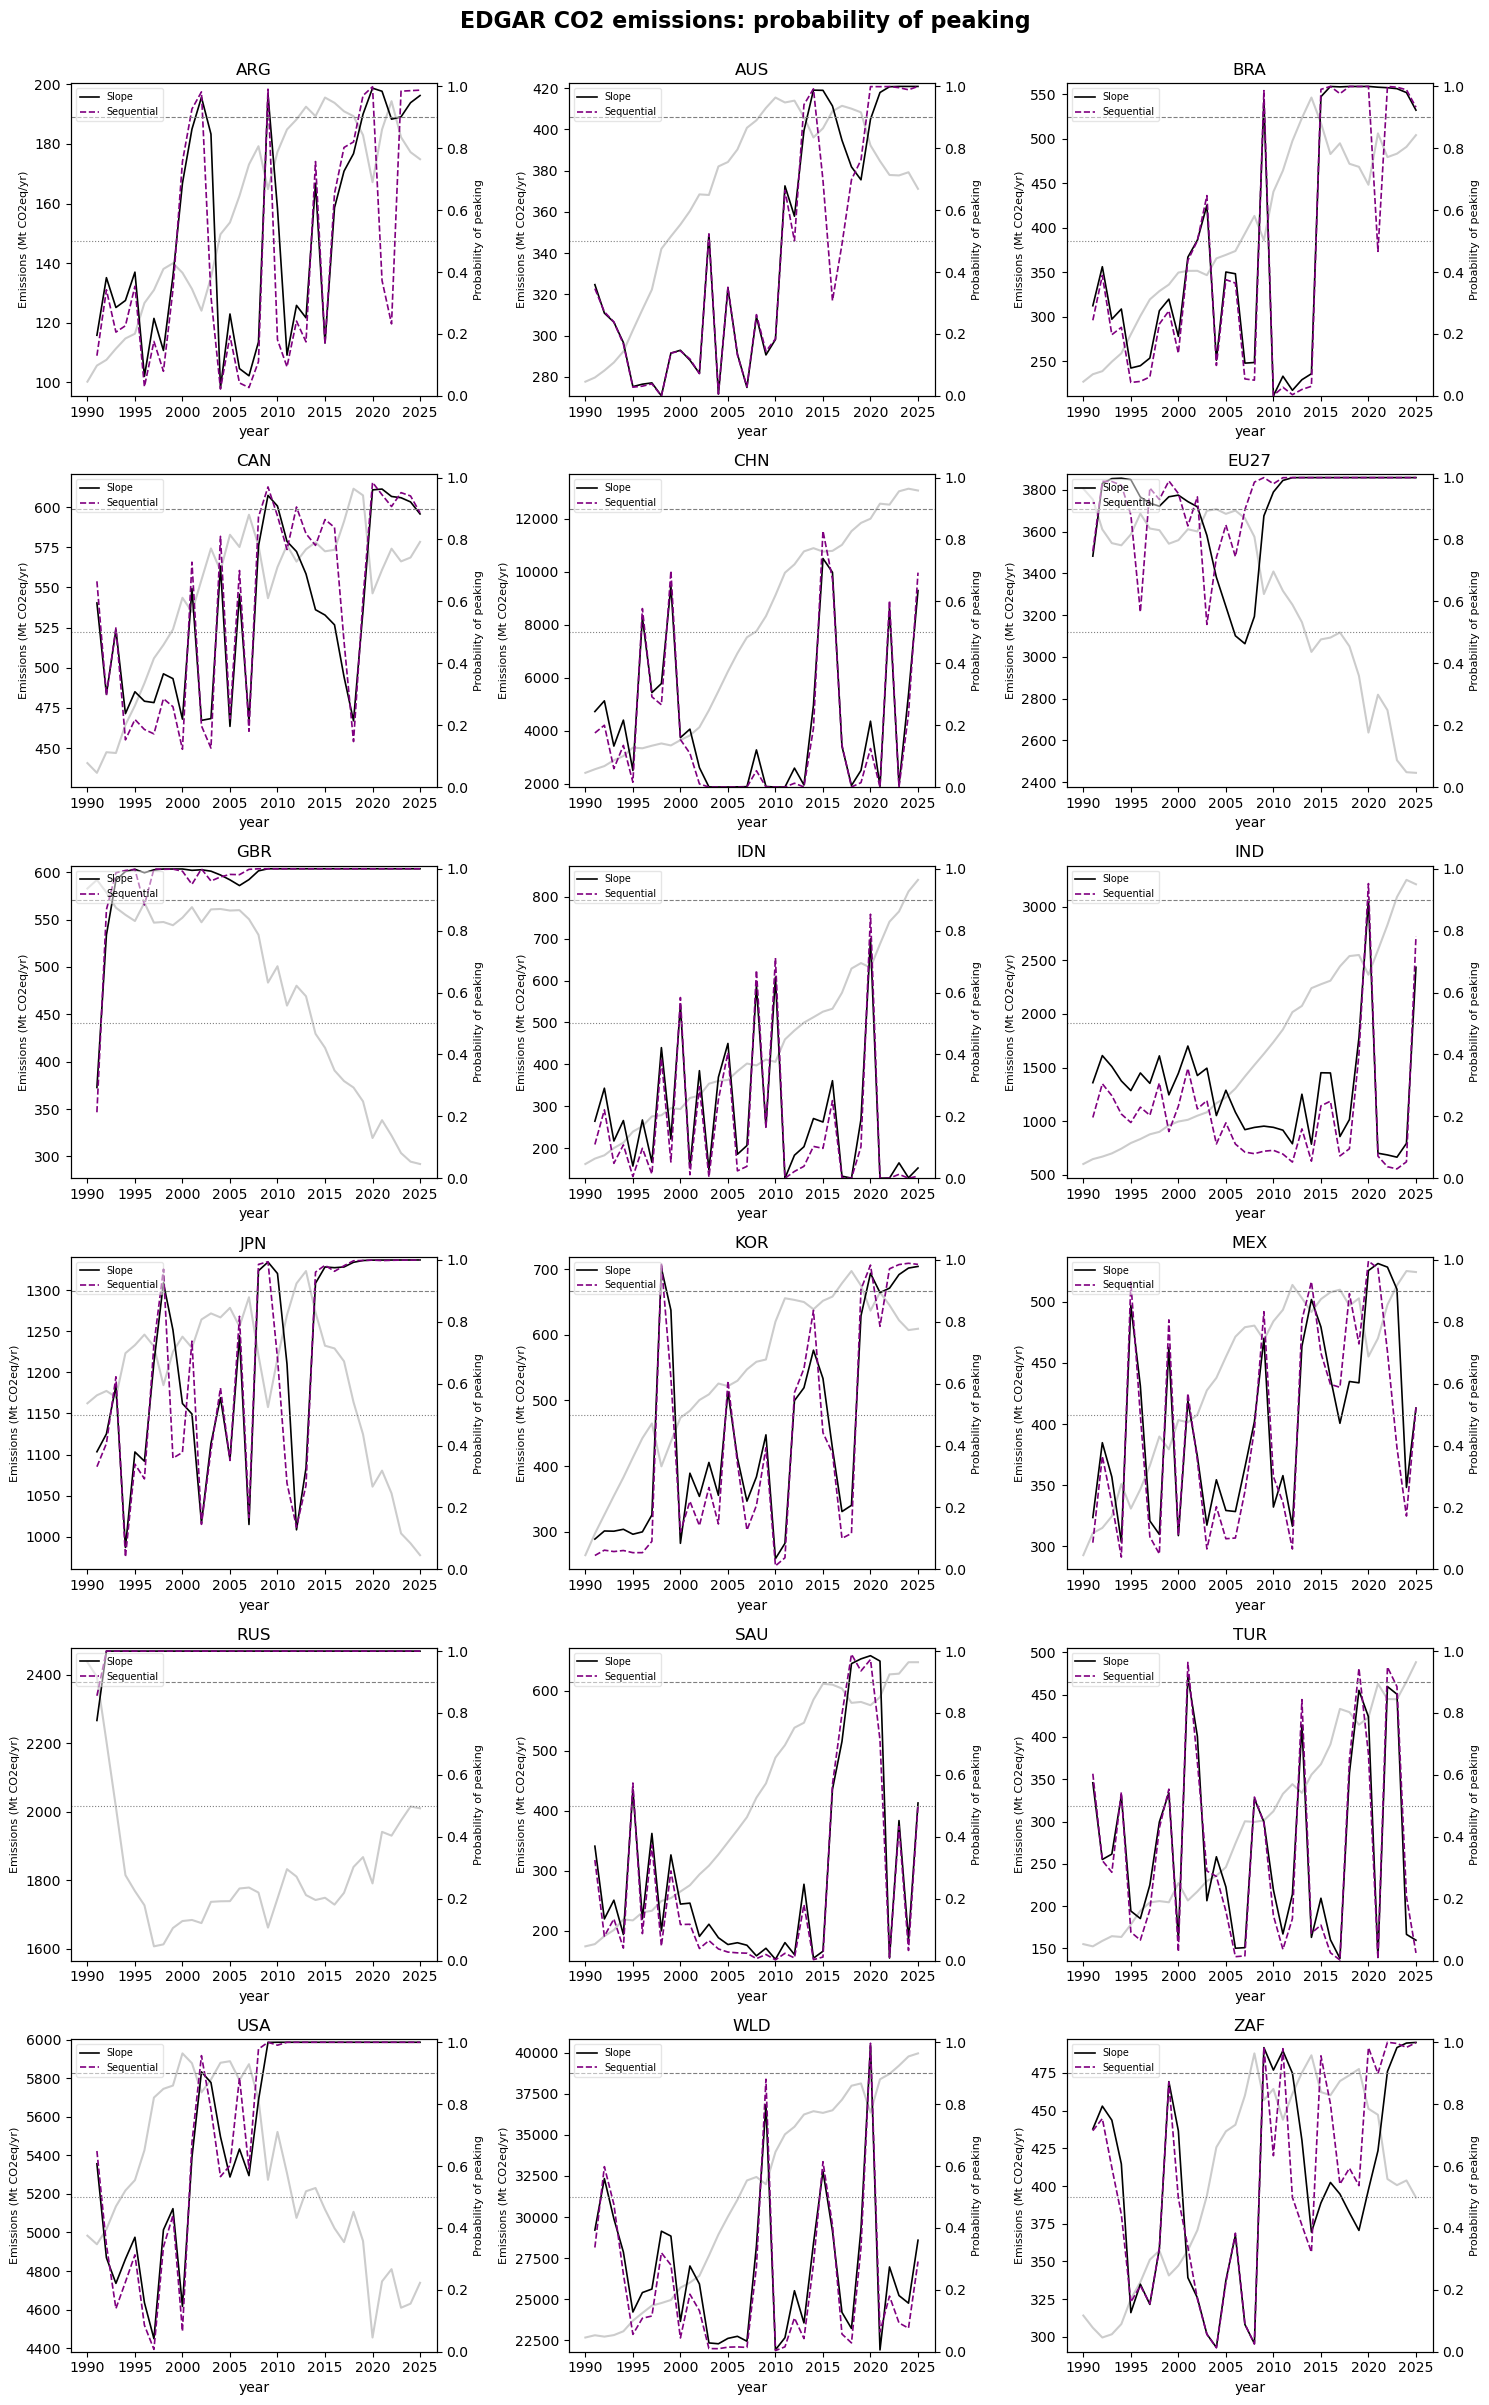

In [62]:
results_plot(prob_df_slope = co2_total_slope, 
             prob_df_sequential = co2_total_sequential,
             historical_data = 'edgar_emissions_incl_lulucf.csv',
             variable = 'Emissions|CO2|Total',
             title="EDGAR CO2 emissions: probability of peaking")

Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36


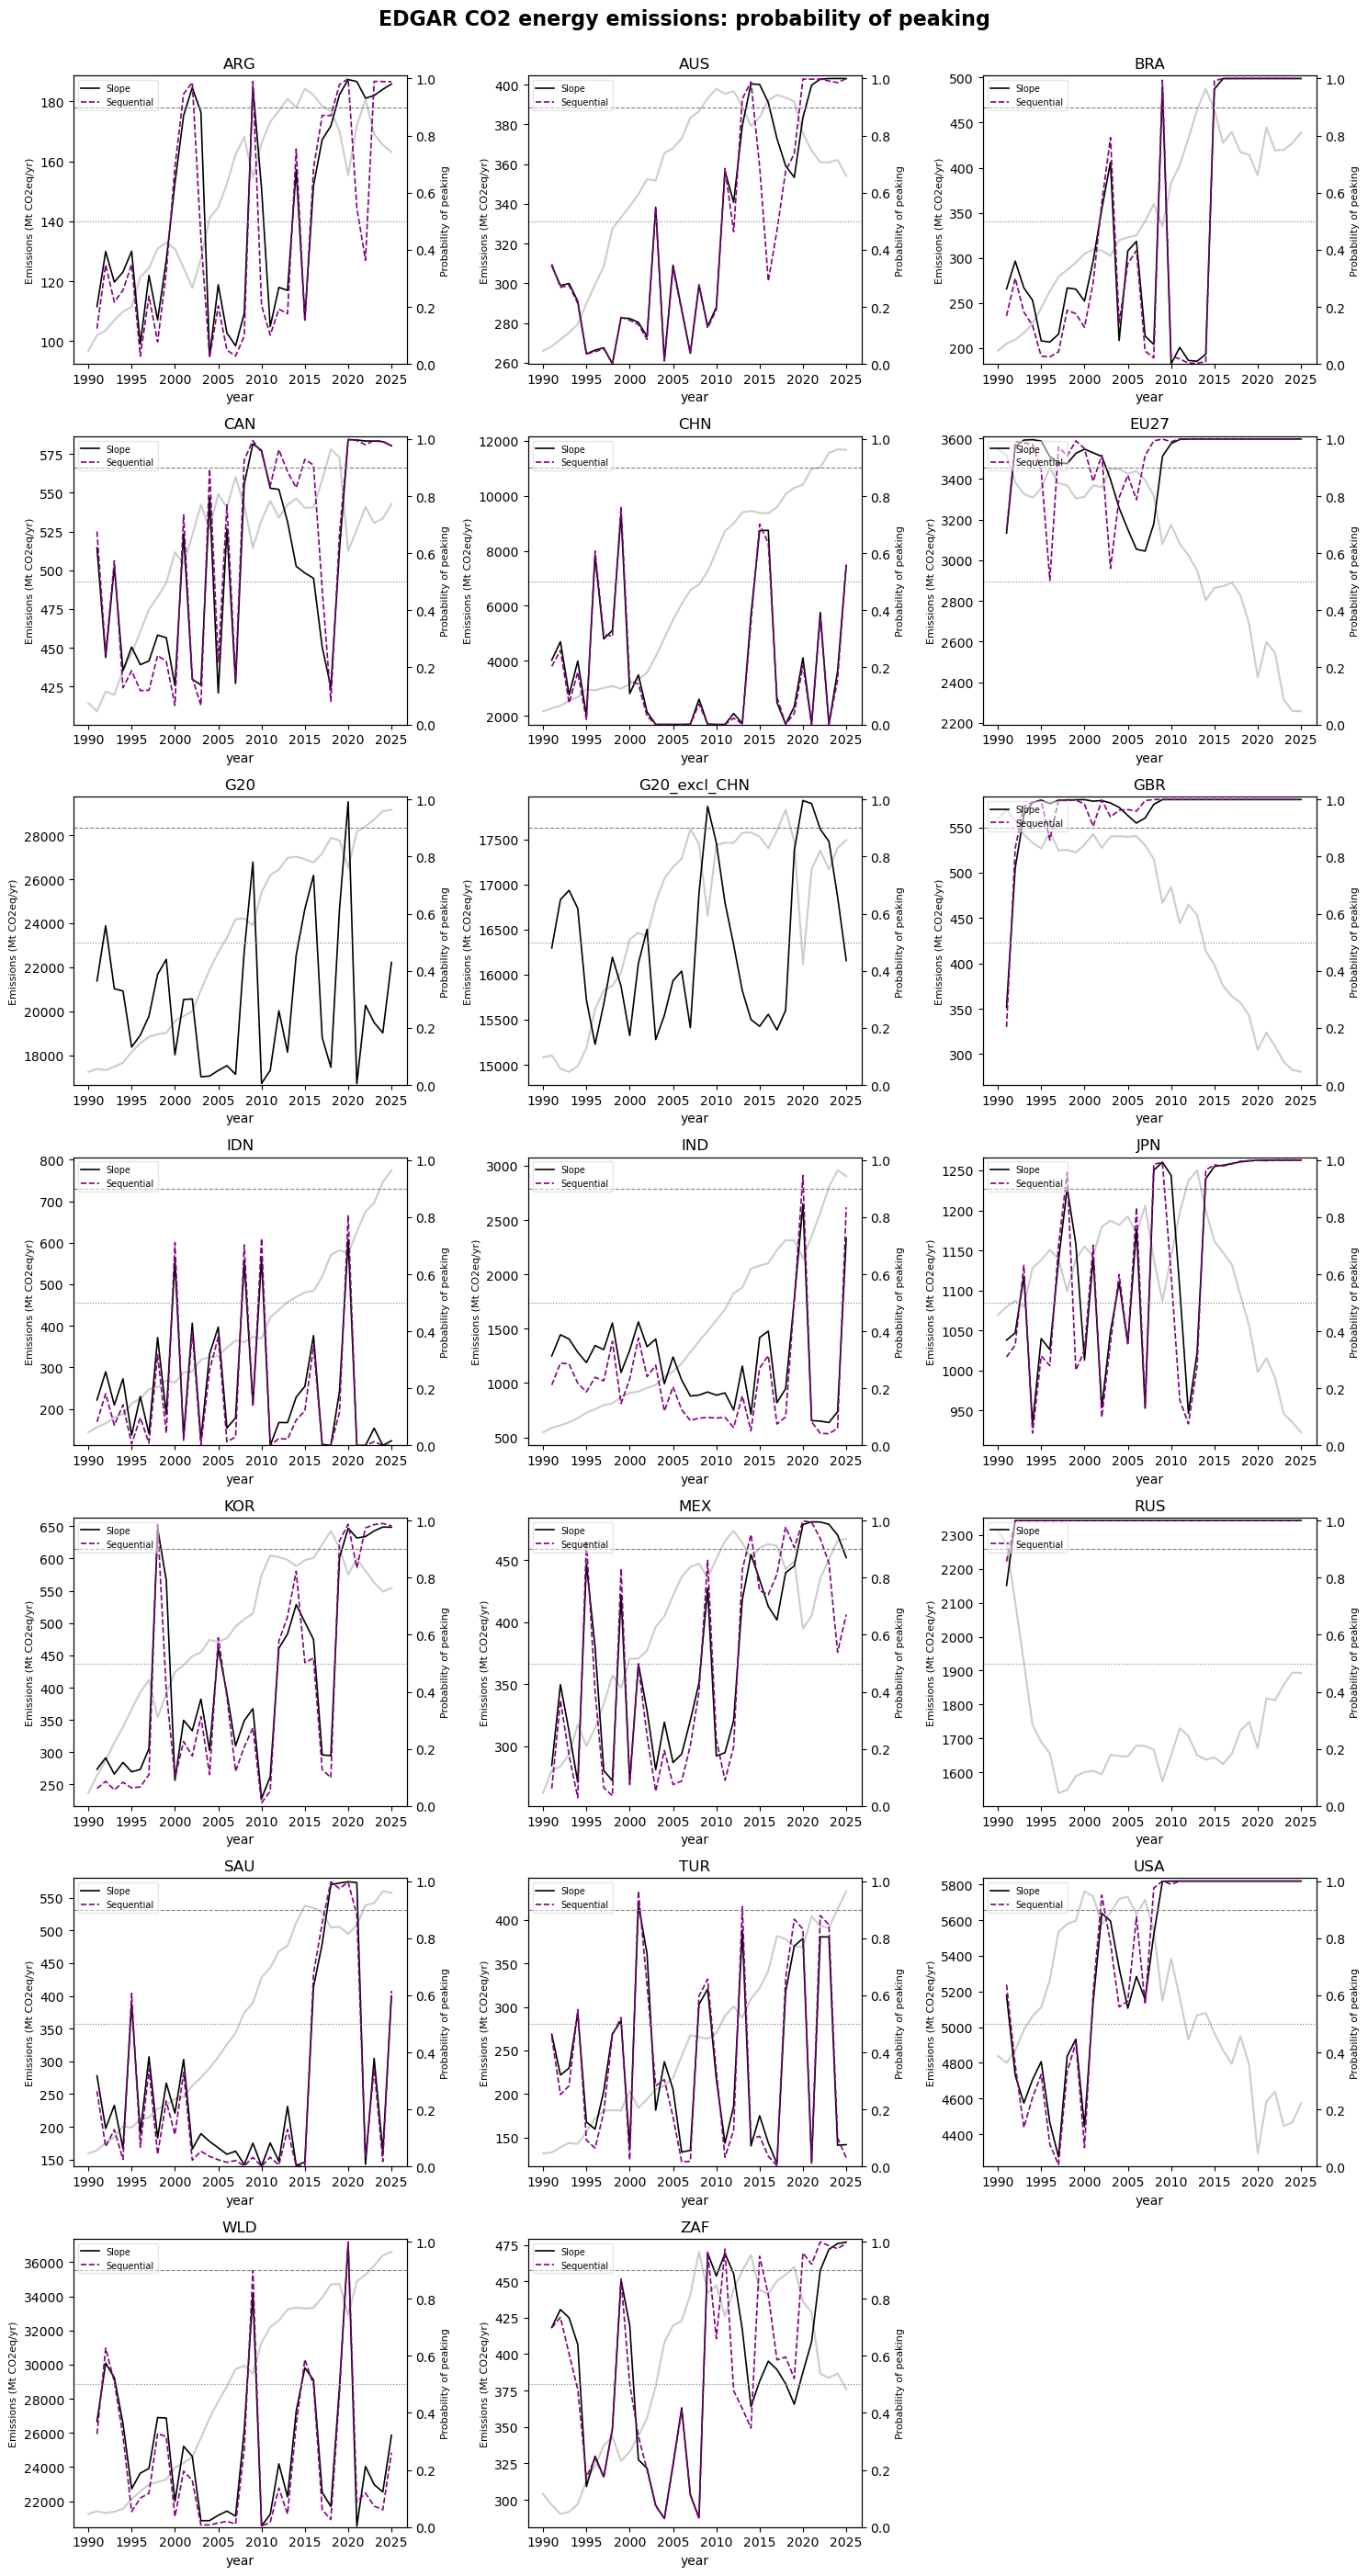

In [63]:
results_plot(prob_df_slope = co2_energy_slope,
             prob_df_sequential = co2_energy_sequential,
             historical_data = 'edgar_energy_co2.csv',
             variable = 'Emissions|CO2|Energy',
             title="EDGAR CO2 energy emissions: probability of peaking")


Loaded historical data: 1990-2025
Data points: 36


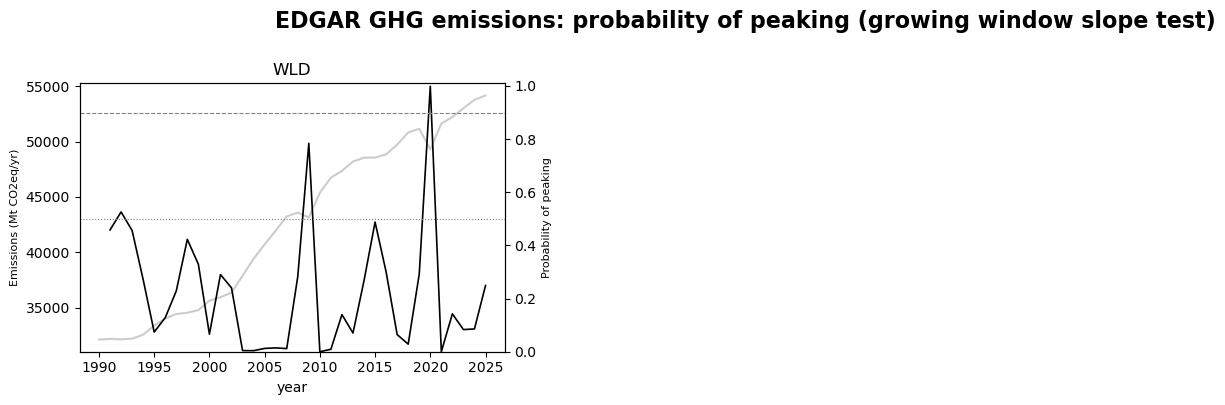

In [64]:
results_plot(prob_df_slope = ghg_slope,
             historical_data = 'edgar_emissions_incl_lulucf.csv',
             variable = 'Emissions|GHG|Total',
             title="EDGAR GHG emissions: probability of peaking (growing window slope test)")

Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36


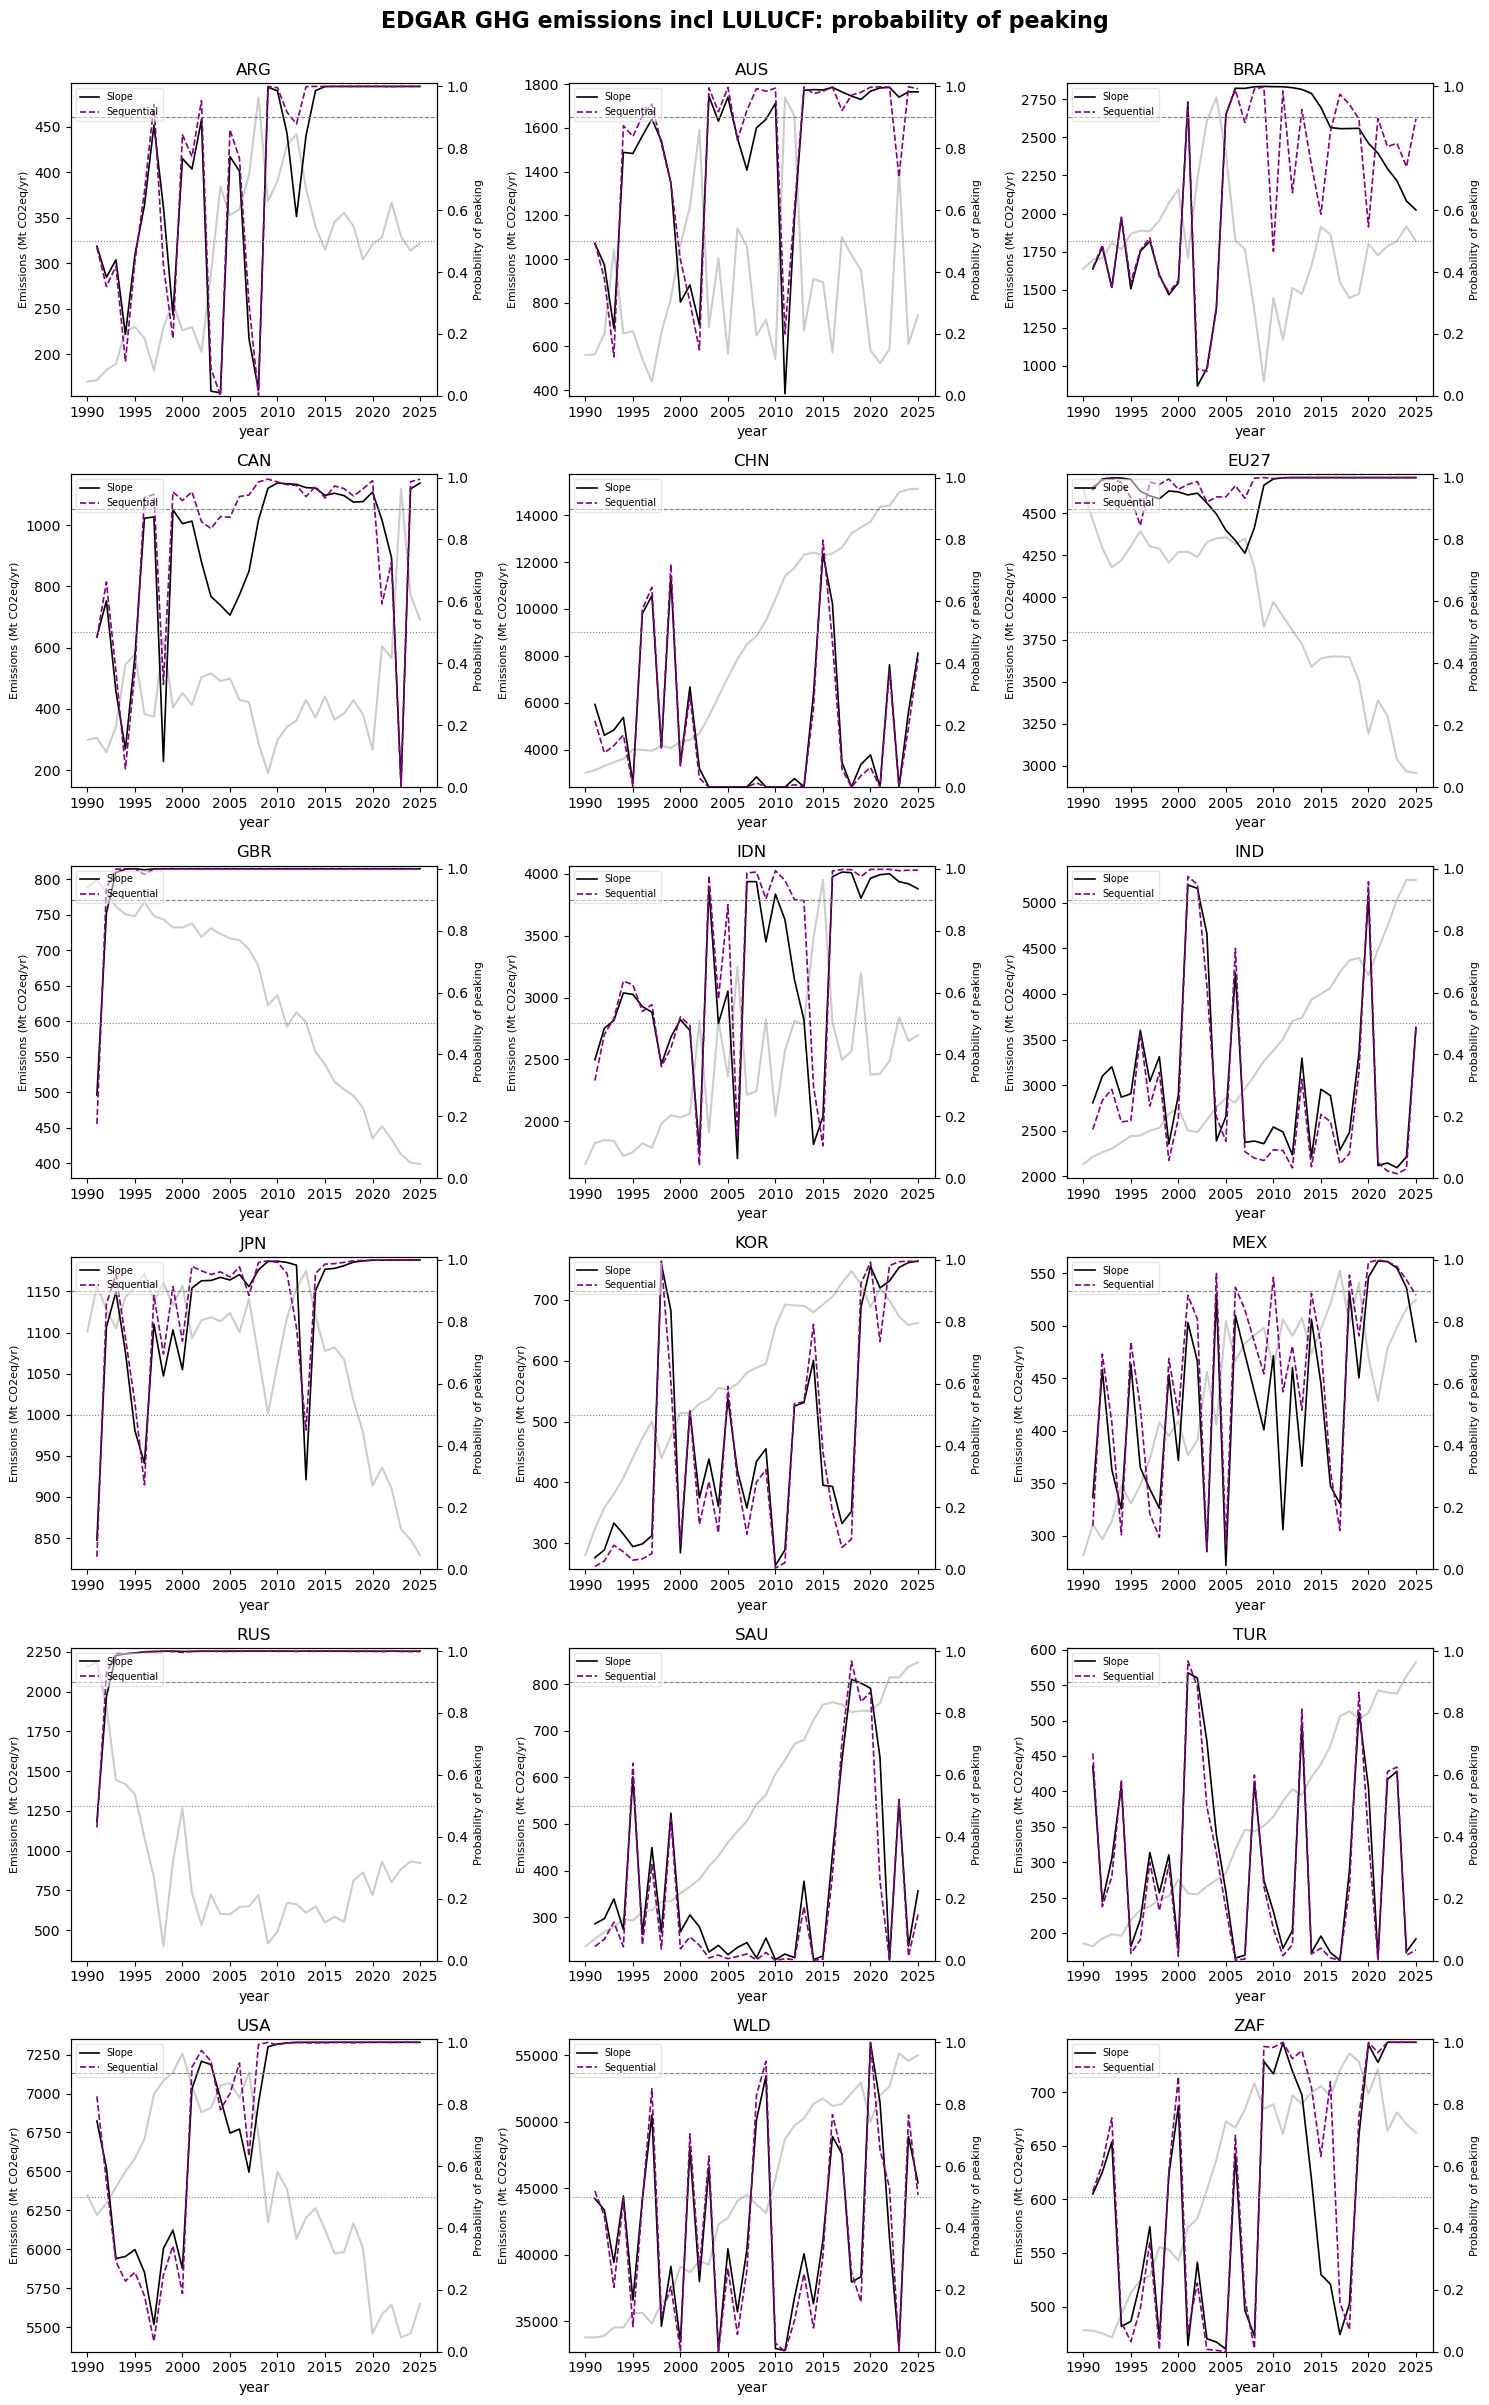

In [68]:
results_plot(prob_df_slope = ghglu_slope, 
             prob_df_sequential = ghglu_sequential,
             historical_data = 'edgar_emissions_incl_lulucf.csv',
             variable = 'Emissions|GHG|Total_incl_LULUCF',
             title="EDGAR GHG emissions incl LULUCF: probability of peaking")


Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36
Loaded historical data: 1990-2025
Data points: 36


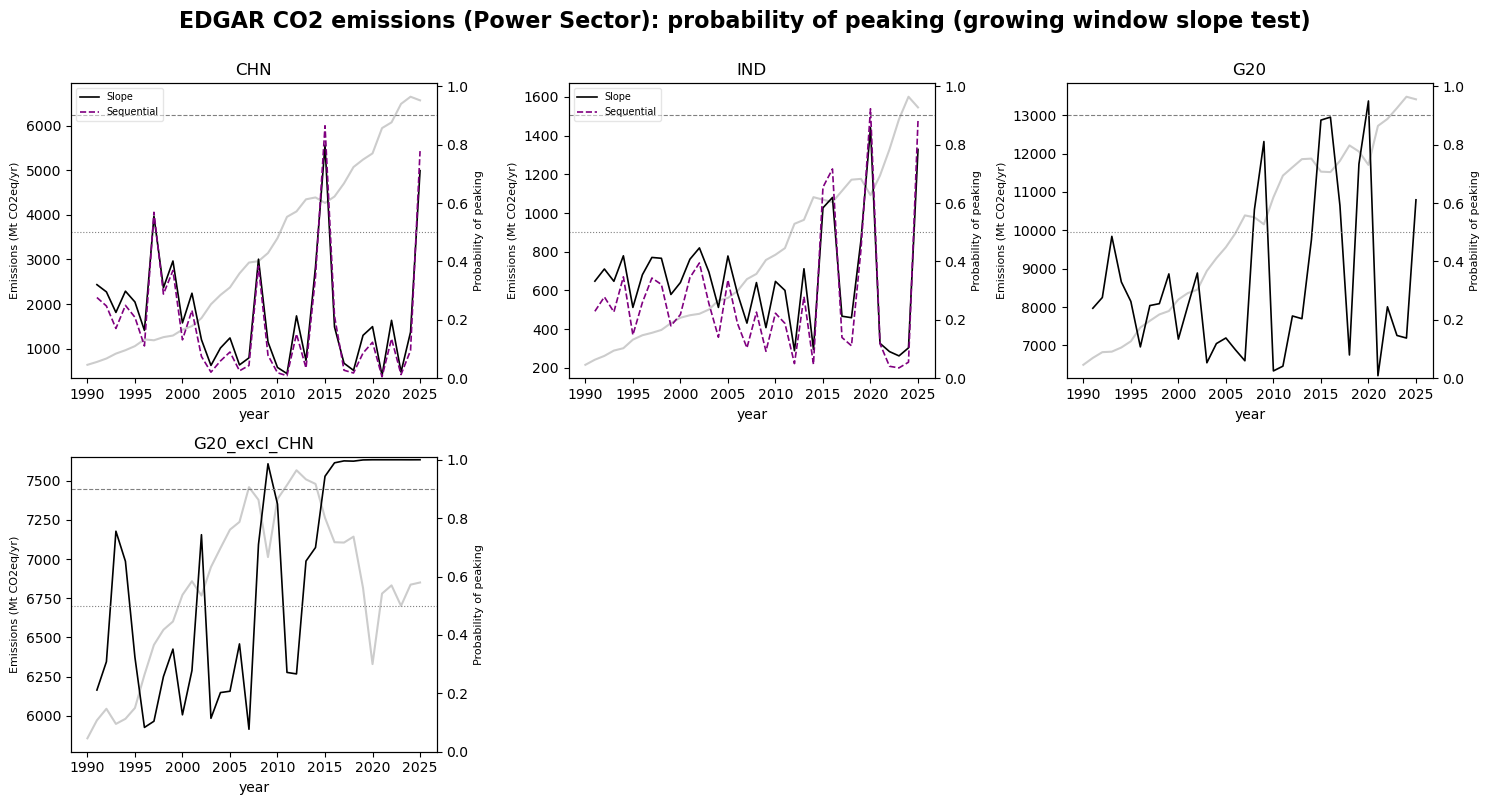

In [72]:
results_plot(prob_df_slope = co2power_slope,
            prob_df_sequential = co2power_sequential,
            countries = ['CHN', 'IND', 'G20', 'G20_excl_CHN'],
            historical_data = 'edgar_emissions_incl_lulucf.csv',
            variable = 'Emissions|CO2|Power Industry',
            title="EDGAR CO2 emissions (Power Sector): probability of peaking (growing window slope test)")